# 02 — Modélisation : prédire D / N / E

Le code est dans `src/modele/` (features, baselines, réseau PyTorch, évaluation) et s'exécute avec `python -m src.modele.entrainement`. Ce notebook présente les résultats sauvegardés dans `docs/resultats/`.

In [1]:
import json
import sys
from pathlib import Path

RACINE = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RACINE))
import matplotlib.pyplot as plt
import pandas as pd

pd.set_option("display.max_columns", 30)
DATA = RACINE / "app" / "data"
RES = RACINE / "docs" / "resultats"
ORANGE, VERT, GRIS = "#E07000", "#006B45", "#9A9A94"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#E6E8EB", "axes.axisbelow": True})

## 1. Variables (connues avant le match)

In [2]:
from src.modele.features import matrice

f = pd.read_csv(RES / "jeu_features.csv", parse_dates=["date_match"])
X = matrice(f)
print(X.shape); X.describe().T.round(2)

(1934, 26)


,count,mean,std,min,25%,50%,75%,max
elo_dom,1934.0,1502.65,53.21,1364.18,1465.82,1496.75,1531.31,1690.05
elo_ext,1934.0,1499.42,53.36,1358.99,1462.38,1494.38,1529.28,1698.77
forme5_dom,1934.0,1.35,0.64,0.00,1.00,1.40,1.80,3.00
forme5_ext,1934.0,1.36,0.65,0.00,1.00,1.40,1.80,3.00
forme10_dom,1934.0,1.36,0.50,0.00,1.00,1.35,1.70,3.00
forme10_ext,1934.0,1.36,0.51,0.00,1.00,1.30,1.70,3.00
bp5_dom,1934.0,1.03,0.51,0.00,0.60,1.00,1.40,4.00
bp5_ext,1934.0,1.04,0.51,0.00,0.60,1.00,1.40,3.40
bc5_dom,1934.0,1.03,0.48,0.00,0.60,1.00,1.40,3.20
bc5_ext,1934.0,1.03,0.49,0.00,0.75,1.00,1.40,4.00


## 2. Protocole

- 2016-17 : initialisation de l'Elo et de la forme (pas d'apprentissage).
- Validation glissante : chaque saison 2021-22 → 2025-26 est prédite par un modèle entraîné sur les saisons précédentes.
- Choix du modèle : meilleure log-loss moyenne sur 2021 → 2024.
- Test final : 2025-26, jamais utilisé pour un choix.

In [3]:
m = json.loads((RES / "metriques.json").read_text(encoding="utf-8"))
print("Modèle retenu :", m["modele_retenu"]); print("Elo :", m["params_elo"]); print(m["hyperparametres"])

Modèle retenu : elo
Elo : {'k': 15, 'avantage_terrain': 160}
{'logreg_C': 0.003, 'mlp': {'couches': [16], 'dropout': 0.2, 'weight_decay': 0.001}}


## 3. Validation glissante

In [4]:
g = pd.read_csv(RES / "validation_glissante.csv")
display(g.pivot(index="modele", columns="saison_test", values="log_loss").round(4))
g.groupby("modele")[["accuracy", "log_loss", "brier", "rps"]].mean().sort_values("log_loss").round(4)

saison_test,2021,2022,2023,2024,2025
modele,,,,,
boosting,1.0834,1.0650,1.0760,1.0970,1.0976
elo,1.0478,1.0515,1.0858,1.0840,1.0884
foret,1.0607,1.0760,1.0790,1.0830,1.0907
logreg,1.0502,1.0664,1.0693,1.0819,1.0982
mlp,1.0560,1.0738,1.0805,1.0830,1.1028
naif,1.0975,1.0931,1.0938,1.1071,1.0952


,accuracy,log_loss,brier,rps
modele,,,,
elo,0.4374,1.0715,0.6473,0.2207
logreg,0.4258,1.0732,0.6487,0.2220
foret,0.4231,1.0779,0.6517,0.2230
mlp,0.4263,1.0792,0.6526,0.2236
boosting,0.4128,1.0838,0.6559,0.2244
naif,0.3539,1.0974,0.6659,0.2302


## 4. Test final 2025-26

In [5]:
pd.DataFrame(m["resultats_test"]).set_index("libelle")[["accuracy", "log_loss", "brier", "rps"]].round(4)

,accuracy,log_loss,brier,rps
libelle,,,,
Elo,0.3917,1.0884,0.6575,0.2305
Forêt aléatoire,0.4000,1.0907,0.6598,0.2306
Référence naïve,0.3375,1.0952,0.6645,0.2338
Gradient boosting,0.4042,1.0976,0.6633,0.2310
Régression logistique,0.3833,1.0982,0.6645,0.2323
Réseau de neurones,0.3875,1.1028,0.6675,0.2338


## 5. Significativité (bootstrap apparié)

In [6]:
pd.DataFrame({n: {"glissante": f"{b['glissante']['ecart_moyen']:+.4f} [{b['glissante']['ic95'][0]:+.4f} ; {b['glissante']['ic95'][1]:+.4f}]",
                  "test": f"{b['test']['ecart_moyen']:+.4f} [{b['test']['ic95'][0]:+.4f} ; {b['test']['ic95'][1]:+.4f}]"}
              for n, b in m["bootstrap_vs_naif"].items()}).T

,glissante,test
elo,-0.0246 [-0.0392 ; -0.0092],-0.0068 [-0.0377 ; +0.0264]
logreg,-0.0230 [-0.0357 ; -0.0102],+0.0030 [-0.0257 ; +0.0329]
foret,-0.0186 [-0.0325 ; -0.0054],-0.0044 [-0.0349 ; +0.0277]
boosting,-0.0135 [-0.0271 ; -0.0005],+0.0024 [-0.0295 ; +0.0347]
mlp,-0.0170 [-0.0300 ; -0.0036],+0.0077 [-0.0194 ; +0.0375]


Un écart négatif = log-loss plus faible que la référence naïve. Sur ≈ 1 200 matchs de validation glissante, l'intervalle permet de dire si le gain est réel ; sur les 240 matchs du test seul, l'incertitude est trop grande pour conclure.

## 6. Matrice de confusion et calibration

elo


,réel D,réel N,réel E
prédit D,51,39,52
prédit N,0,0,0
prédit E,30,25,43


logreg


,réel D,réel N,réel E
prédit D,42,38,45
prédit N,12,8,8
prédit E,27,18,42


mlp


,réel D,réel N,réel E
prédit D,47,35,50
prédit N,10,6,5
prédit E,24,23,40


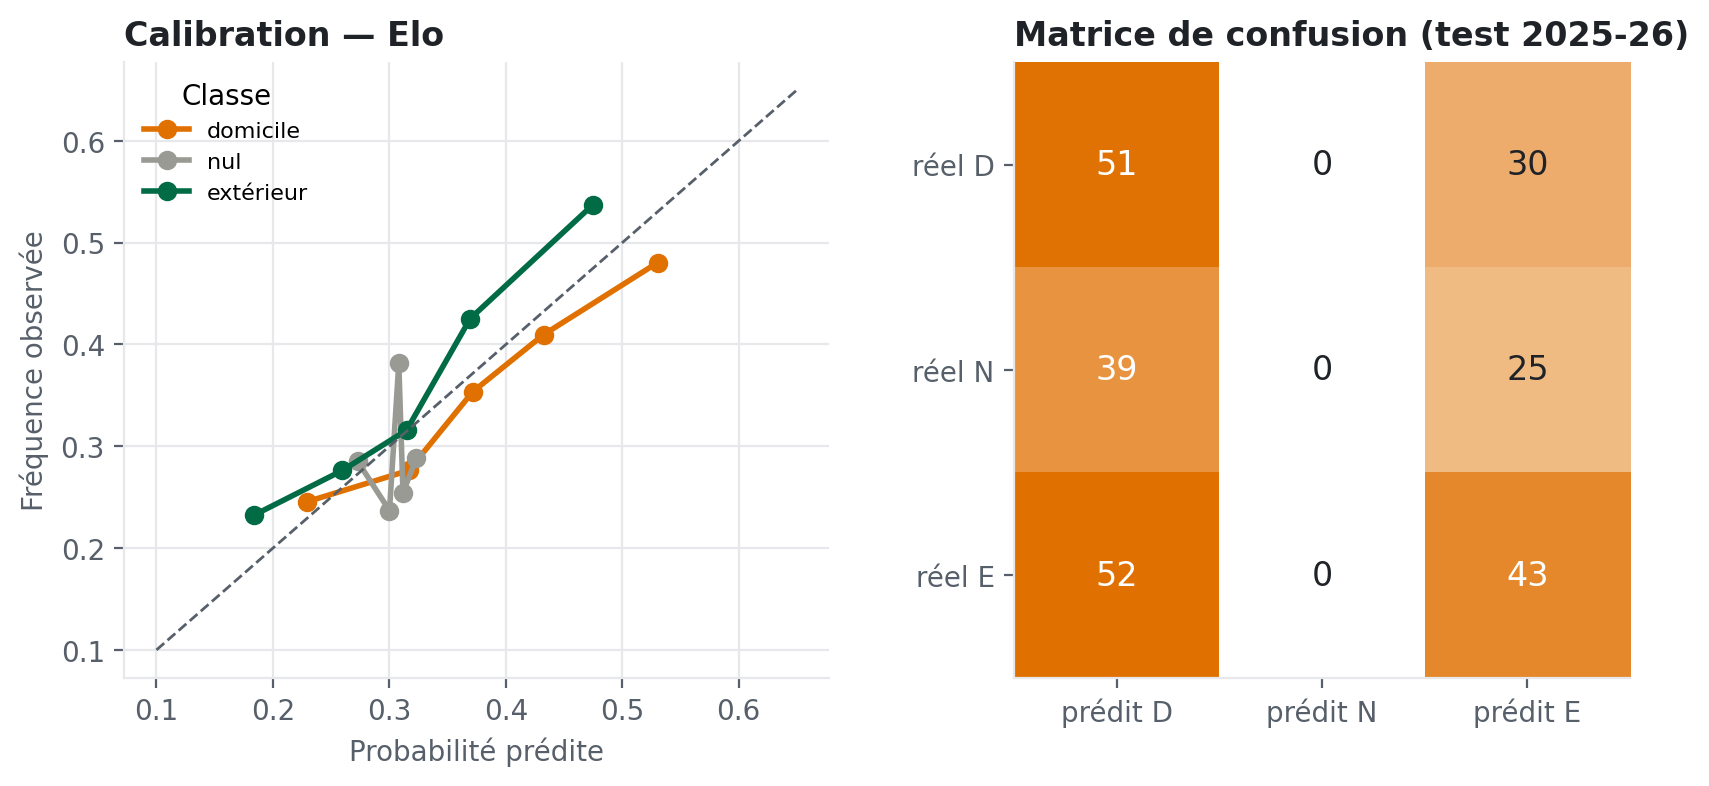

In [7]:
for nom in ["elo", "logreg", "mlp"]:
    print(nom); display(pd.DataFrame(m["confusions"][nom]).T)
from IPython.display import Image

Image(str(RACINE / "docs" / "figures" / "09_calibration_confusion.png"))

## 7. Importance des variables

In [8]:
imp = pd.read_csv(RES / "importance_variables.csv")
imp.groupby("modele").head(6)

,variable,hausse_log_loss,ecart_type,modele
0,elo_dom,0.002915,0.002811,logreg
1,forme_domicile_dom,0.001831,0.001426,logreg
2,elo_diff,0.001739,0.004232,logreg
3,repos_dom,0.001065,0.000815,logreg
4,rang_dom,0.000361,0.001027,logreg
5,rang_diff,0.000163,0.000835,logreg
26,elo_dom,0.002878,0.003444,foret
27,diff_saison_dom,0.001648,0.001394,foret
28,elo_diff,0.000925,0.005569,foret
29,matchs_saison,0.000500,0.001403,foret


In [9]:
coef = pd.read_csv(RES / "coefficients_logreg.csv", index_col=0)
coef.reindex(coef["coef_D"].abs().sort_values(ascending=False).index).head(10).round(3)

,coef_D,coef_N,coef_E
variable,,,
elo_diff,0.066,0.021,-0.086
elo_dom,0.055,0.004,-0.059
elo_ext,-0.041,-0.026,0.067
ppm_saison_dom,0.036,-0.022,-0.015
forme_domicile_dom,-0.036,0.020,0.016
forme_exterieur_ext,-0.032,0.006,0.026
diff_saison_dom,0.031,-0.047,0.016
ppm_diff,0.028,-0.020,-0.008
bc5_ext,0.027,-0.022,-0.005


## 8. Réseau de neurones : courbe d'apprentissage

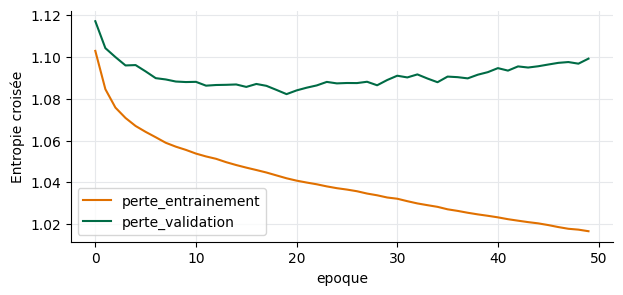

In [10]:
c = pd.read_csv(RES / "courbe_apprentissage_mlp.csv")
ax = c.plot(x="epoque", y=["perte_entrainement", "perte_validation"], color=[ORANGE, VERT], figsize=(7, 3))
ax.set_ylabel("Entropie croisée"); plt.show()

## Conclusion

Dans un championnat serré (≈ 30 % de nuls, ≈ 2 buts par match), un modèle simple fondé sur le score Elo fait aussi bien ou mieux que les modèles complexes. Le réseau de neurones, malgré dropout, pénalité L2, arrêt anticipé et moyenne de 5 graines, n'apporte pas de gain avec ~1 500 matchs d'entraînement : c'est un résultat honnête et attendu. Pistes : buteurs/compositions match par match (API-Football), cotes, modèle de Poisson bivarié (Dixon-Coles) pour mieux prédire les nuls.